In [13]:
# Домашнее задание: дизайн ratio-теста.

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Проверка данных
metrics = pd.read_csv('user_week_metrics.csv', parse_dates=['week_start'])
users = pd.read_csv('users.csv')
counts = ['sessions', 'search_views', 'responses', 'relevant_responses', 'invitations']

print('1. КАЧЕСТВО ДАННЫХ')
print('Строк в истории:', len(metrics))
print('Пользователей в справочнике:', len(users))
print('Уникальных пользователей в истории:', metrics.user_id.nunique())
print('Пропуски:', metrics.isna().sum().sum() + users.isna().sum().sum())
print('Дубликаты (user_id, week_start) и user_id в user.csv:',
      metrics.duplicated(['user_id', 'week_start']).sum(),
      users.duplicated('user_id').sum())
print('Неизвестные user_id:', (~metrics.user_id.isin(users.user_id)).sum())
print('Отрицательные счётчики:', (metrics[counts] < 0).sum().sum())
print('Проверка, что приглашения <= релевантные отклики <= отклики:',
      (metrics.invitations > metrics.relevant_responses).sum() +
      (metrics.relevant_responses > metrics.responses).sum())

weekly = metrics.assign(
    zero_sessions=(metrics.sessions == 0),
    zero_and_responses=((metrics.sessions == 0) & (metrics.responses > 0))
).groupby('week_start').agg(
    sessions=('sessions', 'sum'),
    responses=('responses', 'sum'),
    zero_sessions=('zero_sessions', 'sum'),
    zero_and_responses=('zero_and_responses', 'sum'))
weekly['conversion_pct'] = 100 * weekly.responses / weekly.sessions
print('\nТаблица по неделям: сессии, отклики, строки с нулём сессий,\n'
      'строки с нулём сессий и ненулевыми откликами, конверсия (%)')
print(weekly.round(2).to_string())



1. КАЧЕСТВО ДАННЫХ
Строк в истории: 563375
Пользователей в справочнике: 160000
Уникальных пользователей в истории: 154062
Пропуски: 0
Дубликаты (user_id, week_start) и user_id в user.csv: 0 0
Неизвестные user_id: 0
Отрицательные счётчики: 0
Проверка, что приглашения <= релевантные отклики <= отклики: 0

Таблица по неделям: сессии, отклики, строки с нулём сессий,
строки с нулём сессий и ненулевыми откликами, конверсия (%)
            sessions  responses  zero_sessions  zero_and_responses  conversion_pct
week_start                                                                        
2026-03-09    267969      99690              0                   0           37.20
2026-03-16    280040     104497              0                   0           37.32
2026-03-23    257940      96518              0                   0           37.42
2026-03-30    195245      99272           8763                4118           50.84
2026-04-06    289642     108564              0                   0           


2. МЕТРИКИ И MDE ЗА 1-4 НЕДЕЛИ
 weeks  users  target_pct  guard_pct  info_pct  mde_target_pct  mde_guard_pct
     1  73382     37.4821     6.7932   49.0264          3.0568         7.2042
     2 108383     37.3446     6.7426   48.9761          2.7296         5.5567
     3 126832     37.2756     6.7420   48.9371          2.5914         4.8258
     4 137482     37.2965     6.7213   48.8399          2.5462         4.4324

ТРИ НЕДЕЛИ: ЧИСЛА ДЛЯ ПОДСТАНОВКИ В ФОРМУЛЫ
Пользователей: 126832 ; в группе: 63416
Сессий: 814211 ; откликов: 303502 ; релевантных откликов: 148525 ; приглашений: 20462
Цель: R = 0.372756; среднее X = 6.419602; Var(Y-RX) = 15.534247; v = 0.376942; SE = 0.00344788; MDE абсолютный = 0.00965954; MDE = 2.5914%
Guardrail: G = 0.067420; среднее X = 2.392945; Var(Y-GX) = 0.244870; v = 0.042763; SE = 0.00116132; MDE абсолютный = 0.00325353; MDE = 4.8258%
Информационная Q = 0.489371 (48.94%)
Ошибочный MDE при независимых сессиях: 0.8055%; занижение в 3.2171 раза


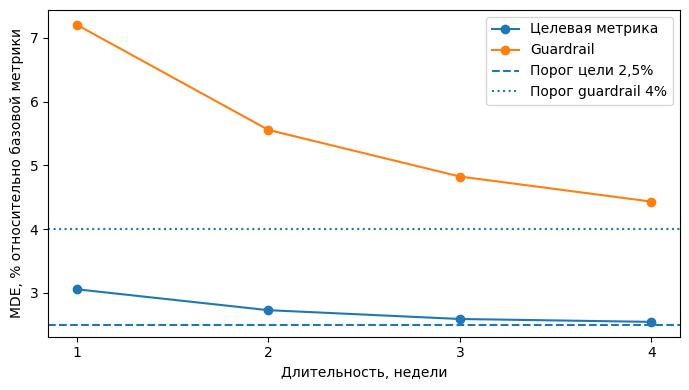

In [14]:
# 2. Расчёт MDE для экспериментов длительностью от 1 до 4 недель
start = pd.Timestamp('2026-04-06')

from statistics import NormalDist

alpha = 0.05   # Уровень значимости 5%
power = 0.80   # Мощность теста 80%

z_alpha = NormalDist().inv_cdf(1 - alpha / 2)
z_power = NormalDist().inv_cdf(power)


def user_window(weeks):
    # Данные за указанное количество недель
    rows = metrics[(metrics.week_start >= start) &
                   (metrics.week_start < start + pd.Timedelta(weeks=weeks))]
    # Одна строка  - информация об одном пользователе
    return rows.groupby('user_id')[
        ['sessions', 'responses', 'relevant_responses', 'invitations']
    ].sum()

# Вычисление ratio-метрики 
def ratio_stats(x, y):
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    ratio = y.sum() / x.sum()

    # Линеаризация
    residual_variance = np.var(y - ratio * x, ddof=1)
    # Дельта-метод
    delta_variance = residual_variance / x.mean()**2

    return ratio, delta_variance, residual_variance


def mde_stats(x, y):
    ratio, delta_variance, residual_variance = ratio_stats(x, y)
    # Разделение на контрольную и тестовую группы 
    n_a = len(x) // 2
    n_b = len(x) - n_a

    se = math.sqrt(delta_variance * (1 / n_a + 1 / n_b)) # Стандартная ошибка разности ratio-метрик
    mde_abs = (z_alpha + z_power) * se 
    mde_relative = mde_abs / ratio 

    return ratio, delta_variance, residual_variance, se, mde_abs, mde_relative


results = []

# Mетрики и MDE для периодов от 1 до 4 недель
for weeks in range(1, 5):
    data = user_window(weeks)
    target = mde_stats(data.sessions, data.responses) # Целевая метрика: отклики / сессию
    guard = mde_stats(data.responses, data.invitations) # Guardrail: приглашения / отклики
    info = data.relevant_responses.sum() / data.responses.sum() # Информационная метрика: релевантные отклики / все отклики.

    naive_se = math.sqrt(
        target[0] * (1 - target[0]) * 4 / data.sessions.sum()
    )

    naive_mde = (z_alpha + z_power) * naive_se / target[0]

    # Результаты для каждой длительности в процентах
    results.append([
        weeks,
        len(data),
        100 * target[0],
        100 * guard[0],
        100 * info,
        100 * target[5],
        100 * guard[5],
        100 * naive_mde,
        target[5] / naive_mde
    ])

# Таблица результатов
result = pd.DataFrame(results, columns=[
    'weeks', 'users', 'target_pct', 'guard_pct', 'info_pct',
    'mde_target_pct', 'mde_guard_pct', 'naive_mde_pct', 'factor'
])

# Основные показатели для всех четырёх периодов
print('\n2. МЕТРИКИ И MDE ЗА 1-4 НЕДЕЛИ')
print(result[['weeks', 'users', 'target_pct', 'guard_pct', 'info_pct',
              'mde_target_pct', 'mde_guard_pct']].round(4).to_string(index=False))

data = user_window(3)

# Вычисление показателей для трёхнедельного периода
target = mde_stats(data.sessions, data.responses)
guard = mde_stats(data.responses, data.invitations)
info = data.relevant_responses.sum() / data.responses.sum()

selected = result.iloc[2]
print('\nТРИ НЕДЕЛИ: ЧИСЛА ДЛЯ ПОДСТАНОВКИ В ФОРМУЛЫ')
print('Пользователей:', len(data), '; в группе:', len(data) // 2)
print('Сессий:', data.sessions.sum(), '; откликов:', data.responses.sum(),
      '; релевантных откликов:', data.relevant_responses.sum(),
      '; приглашений:', data.invitations.sum())
print('Цель: R = {:.6f}; среднее X = {:.6f}; Var(Y-RX) = {:.6f};'
      ' v = {:.6f}; SE = {:.8f}; MDE абсолютный = {:.8f}; MDE = {:.4f}%'.format(
          target[0], data.sessions.mean(), target[2], target[1], target[3],
          target[4], 100 * target[5]))
print('Guardrail: G = {:.6f}; среднее X = {:.6f}; Var(Y-GX) = {:.6f};'
      ' v = {:.6f}; SE = {:.8f}; MDE абсолютный = {:.8f}; MDE = {:.4f}%'.format(
          guard[0], data.responses.mean(), guard[2], guard[1], guard[3],
          guard[4], 100 * guard[5]))
print('Информационная Q = {:.6f} ({:.2f}%)'.format(info, 100 * info))
print('Ошибочный MDE при независимых сессиях: {:.4f}%;'
      ' занижение в {:.4f} раза'.format(selected.naive_mde_pct, selected.factor))


# График зависимости MDE от длительности эксперимента.
plt.figure(figsize=(7, 4))
plt.plot(result.weeks, result.mde_target_pct, 'o-', label='Целевая метрика')
plt.plot(result.weeks, result.mde_guard_pct, 'o-', label='Guardrail')
plt.axhline(2.5, linestyle='--', label='Порог цели 2,5%')
plt.axhline(4.0, linestyle=':', label='Порог guardrail 4%')
plt.xticks([1, 2, 3, 4])
plt.xlabel('Длительность, недели')
plt.ylabel('MDE, % относительно базовой метрики')
plt.legend()
plt.tight_layout()
plt.savefig('mde_consistent.png', dpi=150)
plt.show()


In [15]:
# 3. Выбор длительности эксперимента и оценка изменений

# Функция стандартного нормального распределения
def normal_cdf(t):
    return 0.5 * (1 + math.erf(t / math.sqrt(2)))

# Мощность двустороннего теста для заданного изменения метрики
def two_sided_power(relative_effect, relative_se):
    z = relative_effect / relative_se
    return normal_cdf(z - z_alpha) + normal_cdf(-z - z_alpha)

# Мощность обнаружения роста целевой метрики на 2,5%.
power_target = two_sided_power(0.025, target[3] / target[0])

# Мощность обнаружения снижения guardrail на 4%.
power_guard = two_sided_power(0.04, guard[3] / guard[0])

print('\n3. ТРИ НЕДЕЛИ И БИЗНЕС-ПОРОГИ')
print('Период: 06.09.2027-26.09.2027 (маркетинговая кампания с 4-й недели)')
print('Мощность для роста цели +2,5%: {:.1f}%'.format(100 * power_target))
print('Мощность для падения guardrail -4%: {:.1f}%'.format(100 * power_guard))



3. ТРИ НЕДЕЛИ И БИЗНЕС-ПОРОГИ
Период: 06.09.2027-26.09.2027 (маркетинговая кампания с 4-й недели)
Мощность для роста цели +2,5%: 77.1%
Мощность для падения guardrail -4%: 64.1%


In [16]:
# 5. A/A-тест на выбранном трёхнедельном периоде
x = data.sessions.to_numpy(dtype=float)
y = data.responses.to_numpy(dtype=float)
personal = y / x  

# Проводим 1000 случайных разделений пользователей на две группы
seed = int(np.random.default_rng().integers(0, 1000000))
rng = np.random.default_rng(seed)
n_sim = 1000
hits = np.zeros(3, dtype=int)

for i in range(n_sim):
    # Случайно распределяем пользователей в группы A и B
    group_a = rng.random(len(x)) < 0.5
    xa, ya, pa = x[group_a], y[group_a], personal[group_a]
    xb, yb, pb = x[~group_a], y[~group_a], personal[~group_a]

    # Сравнение ratio-метрик с помощью дельта-метода.
    ra, va, _ = ratio_stats(xa, ya)
    rb, vb, _ = ratio_stats(xb, yb)
    z_delta = (ra - rb) / math.sqrt(va / len(xa) + vb / len(xb))

    # Сравнение средних личных ratio пользователей.
    z_personal = (pa.mean() - pb.mean()) / math.sqrt(
        pa.var(ddof=1) / len(pa) + pb.var(ddof=1) / len(pb))

    # z-тест, считающий сессии независимыми.
    pooled = (ya.sum() + yb.sum()) / (xa.sum() + xb.sum())
    z_events = (ra - rb) / math.sqrt(
        pooled * (1 - pooled) * (1 / xa.sum() + 1 / xb.sum()))

    # Вычисляем p-value для каждого способа и считаем количество случаев, когда p-value меньше 0.05.
    p_values = [math.erfc(abs(z) / math.sqrt(2))
                for z in (z_delta, z_personal, z_events)]
    hits += np.array(p_values) < 0.05

    # Проверяем равномерность распределения пользователей для первого случайного разбиения.
    if i == 0:
        expected = len(x) / 2
        chi2 = ((len(xa) - expected)**2 + (len(xb) - expected)**2) / expected
        p_srm = math.erfc(math.sqrt(chi2 / 2))

        print('\n5. SRM ПЕРВОГО РАЗБИЕНИЯ')
        print('A:', len(xa), '; B:', len(xb), '; ожидание:', expected)
        print('chi2 = {:.5f}; p = {:.5f}'.format(chi2, p_srm))

# Доля ложных срабатываний каждого способа
print('\n5. A/A: ДОЛИ p < 0,05 ИЗ 1000 РАЗБИЕНИЙ')
for name, count in zip(['Дельта-метод', 'Среднее личных ratio',
                        'Событийный z-тест'], hits):
    print('{}: {} / {} = {:.1f}%'.format(
        name, count, n_sim, 100 * count / n_sim))



5. SRM ПЕРВОГО РАЗБИЕНИЯ
A: 63801 ; B: 63031 ; ожидание: 63416.0
chi2 = 4.67469; p = 0.03061

5. A/A: ДОЛИ p < 0,05 ИЗ 1000 РАЗБИЕНИЙ
Дельта-метод: 44 / 1000 = 4.4%
Среднее личных ratio: 53 / 1000 = 5.3%
Событийный z-тест: 530 / 1000 = 53.0%
